# VIII.2 - Travaux pratiques

Dans cette séance de travaux pratiques, l'objectif est de vous faire implémenter par vous-même l'apprentissage d'un premier réseau de neurones simple. En pratique, il existe de nombreuses bibliothèques qui implémentent à notre place les routines qui réalisent cet apprentissage. Toutefois, il est très formateur de manipuler les concepts de base au moins une fois pour comprendre comment fonctionnent les outils que nous utiliseront plus tard, comme Keras.

## Jeu de données MNIST

Pour cette séance, nous travaillerons avec la base de données MNIST. Elle est constituée de 70000 images (60000 images en apprentissage, 10000 en test) de chiffres manuscrits en noir et blanc. L'objectif est d'identifier automatiquement le chiffre à partir de l'image.

Commençons par importer les données. Comme il s'agit d'un jeu de données très classique et courant, il est disponible de base dans de nombreuses bibliothèques, comme Keras. Cela nous permet de l'importer directement en une ligne de code:

In [4]:
from keras.datasets import mnist
import numpy as np
# Import de MNIST depuis Keras
(X_train, y_train), (X_test, y_test) = mnist.load_data()
# Transformation des images 28x28 en vecteur de dimension 784
X_train = X_train.reshape(60000, 784).astype('float32')
X_test = X_test.reshape(10000, 784).astype('float32')

# l'ordre des dimension est sans importance pour le percpetron contrairement à la representation graphique
# Créer une permutation aléatoire
indices = np.random.permutation(len(X_train))
indices2 = np.random.permutation(len(X_test))
# Mélanger les images et les labels de la même manière
X_train = X_train[indices]
y_train = y_train[indices]
X_test = X_test[indices2]
y_test = y_test[indices2]

# Normalisation entre 0 et 1
X_train /= 255
X_test /= 255

# Affichage du nombre de'exemples
print(f"{X_train.shape[0]} exemples d'apprentissage")
print(f"{X_test.shape[0]} exemples de test")

60000 exemples d'apprentissage
10000 exemples de test


<div class="admonition-question admonition">

**Question**

Afficher à l'aide de matplotlib les premières images du jeu d'apprentissage. La fonction `plt.imshow()` (cf. [sa documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html)) peut vous être utile.

</div>

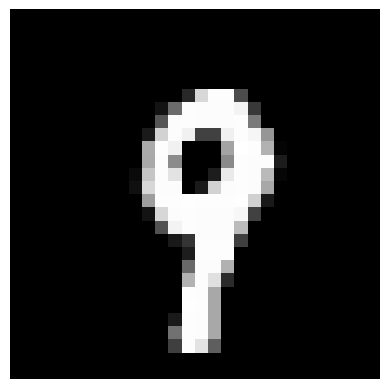

In [5]:
import numpy as np
import matplotlib.pyplot as plt
#print(X_train[1])

plt.imshow(X_train[0].reshape(28, 28) , cmap='gray', vmin=0, vmax=1)
plt.axis('off')
plt.show()


<div class="admonition-question admonition">

**Question**

Quel est l'espace dans lequel se trouvent les images ? Quelle est sa dimension ?

</div>

## Régression logistique

### Modèle de prédiction

Nous allons implémenter un modèle de classification linéaire simple : la régression logistique. Concrètement, la régression logistique est équivalente à un réseau de neurones à une seule couche. Il s'agit d'une projection du vecteur d'entrée $\mathbf{x_i}$ par un vecteur de paramètres $\mathbf{w_{c}}$, plus un biais sclaaire $b_c$, pour chaque classe. Le schéma ci-dessous illustre le modèle de régression logistique avec un réseau de neurones.

![](figures/LR.png)

En l'occurrence, pour MNIST $\mathbf{x}_i$ est de dimension 784 et il y a dix chiffres possibles, donc 10 classes différentes. Dans notre cas, on considère que l'image d'entrée est représentée sous sa forme « aplatie », c'est-à-dire un vecteur (1, 784).

Pour simplifier les notations, on regroupe l'ensemble des jeux de paramètres $\mathbf{w_{c}}$ pour les 10 classes possibles dans une unique matrice $\mathbf{W}$ de dimensions $784\times 10$. De la même façon, les biais sont regroupés dans un vecteur $\mathbf{b}$ de longueur 10. La sortie de la régression logistique est un vecteur contenant une activation pour chaque classe, c'est-à-dire $\mathbf{\hat{s_i}} =\mathbf{x_i} \mathbf{W} + \mathbf{b}$ de dimensions (1, 10).

Afin de transformer les activations en de sortie en probabilités pour une distribution catégorielle, on ajoute une fonction d'activation de *softmax* sur $\mathbf{\hat{y_i}} = \sigma(\mathbf{s_i})$. Cela nous permet d'obtenir en sortie un vecteur de prédictions $\mathbf{\hat{y_i}}$, de dimensions (1, 10), qui représente la probabilité *a posteriori* $p(\mathbf{\hat{y_i}} | \mathbf{x_i})$ pour chacune des 10 classes :

$$
p(\hat{y}_{c,i} | \mathbf{x_i}) ) = \frac{e^{\langle \mathbf{x_i} ; \mathbf{w_{c}}\rangle + b_{c}}}{\sum_{c'=1}^{10} e^{\langle \mathbf{x_i} ; \mathbf{w_{c'}}\rangle + b_{c'}}}
$$

<div class="admonition-question admonition">

**Question**

Quel est le nombre de paramètres du modèle utilisé ? Justifier le calcul.

</div>

In [13]:
## 784x10 poids + 10 biais

### Formulation du problème d'apprentissage

Pour entraîner le réseau de neurones, c'est-à-dire déterminer les valeurs optimales des paramètres $\mathbf{W}$ et $\mathbf{b}$, on va comparer pour chaque exemple d'apprentissage la sortie prédite $\mathbf{\hat{y_i}}$ (équation (softmax)) pour l'image $\mathbf{x_i}$ à la sortie réelle $\mathbf{y_i^*}$ (vérité terrain issue de la supervision). Dans notre cas, on choisit d'encoder la catégorie de l'image $\mathbf{x_i}$ sous forme *one-hot*, c'est-à-dire :

$$
y_{c,i}^* =
\begin{cases}
  1 & \text{si c correspond à l'indice de la classe de } \mathbf{x_i}  \\
  0 & \text{sinon}
\end{cases}
$$

Générons les étiquettes (*labels*) au format *one-hot* ((one-hot)) à l'aide de la fonction `to_categorical` (cf. [documentation de Keras](https://www.tensorflow.org/api_docs/python/tf/keras/utils/to_categorical)).

In [6]:
from keras.utils import to_categorical
n_classes = 10
# Conversion des étiquettes (int) au format vectoriel one-hot
Y_train = to_categorical(y_train, n_classes)
Y_test = to_categorical(y_test, n_classes)
print(y_train)
print(Y_train)

[9 1 9 ... 6 9 4]
[[0. 0. 0. ... 0. 0. 1.]
 [0. 1. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 1.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 0.]]


L'erreur de prédiction sera définie à l'aide de l'entropie croisée (*cross-entropy*). Cette fonction de coût s'applique entre $\mathbf{\hat{y_i}}$ et $\mathbf{y_i^*}$ par la formule :
$𝓛(\mathbf{\hat{y_i}}, \mathbf{y_i^*}) = -\sum_{c=1}^{10} y_{c,i}^* \log(\hat{y}_{c,i}) = - \log(\hat{y}_{c^*,i})$, où $c^*$ correspond à l'indice de la classe donnée par la supervision pour l'image $\mathbf{x_i}$.

<div class="admonition note">

**Note**

L'entropie croisée correspond en réalité à la divergence de Kullback-Leiber pour des distributions catégorielles. La divergence KL est une mesure de dissimilarité entre distributions de probabilité. Autrement dit, l'erreur que l'on mesure vise à réduire l'écart entre la distribution réelle des catégories et la distribution prédite.

</div>

La fonction de coût finale correspond à l'erreur d'apprentissage, c'est-à-dire la moyenne l'entropie croisée sur l'ensemble de la base d'apprentissage $𝓓$ constituée des $N=60000$ images :

$$
𝓛_{\mathbf{W},\mathbf{b}}(𝓓)  = - \frac{1}{N}\sum_{i=1}^{N} \log(\hat{y}_{c^*,i})
$$

<div class="admonition-question admonition">

**Question**

La fonction de coût de (CE) est-elle convexe par rapport aux paramètres $\mathbf{W}$, $\mathbf{b}$ du modèle ? Avec un pas de gradient bien choisi, peut-on assurer la convergence vers le minimum global de la solution ?

</div>

### Optimisation du modèle

Nous allons minimiser la fonction de coût à l'aide de l'algorithme de descente de gradient appliqué sur les paramètres $\mathbf{W}$ et $\mathbf{b}$ du modèle de régression logistique. Pour ce faire, nous allons avoir besoin des gradients de l'entropie croisée par rapport à $\mathbf{W}$ ainsi que $\mathbf{b}$. Nous pouvons nous appuyer sur la des dérivées chaînées (*chain rule*, ou théorème de dérivation des fonctions composées) :

$$
\frac{\partial 𝓛}{\partial \mathbf{W}} =  \frac{1}{N}\sum_{i=1}^{N} \frac{\partial 𝓛}{\partial \mathbf{\hat{y_i}}}  \frac{\partial \mathbf{\hat{y_i}}}{\partial \mathbf{s_i}} \frac{\partial \mathbf{s_i}}{\partial \mathbf{W}}
$$

$$
\frac{\partial 𝓛}{\partial \mathbf{b}} =  \frac{1}{N}\sum_{i=1}^{N} \frac{\partial 𝓛}{\partial \mathbf{\hat{y_i}}}  \frac{\partial \mathbf{\hat{y_i}}}{\partial \mathbf{s_i}} \frac{\partial \mathbf{s_i}}{\partial \mathbf{b}}
$$

<div class="admonition-question admonition">

**Question**

Montrer que :

$$
\frac{\partial 𝓛}{\partial \mathbf{s_i}} = \mathbf{\delta^y_i} = \frac{\partial 𝓛}{\partial \mathbf{\hat{y_i}}}  \frac{\partial \mathbf{\hat{y_i}}}{\partial \mathbf{s_i}} = \mathbf{\hat{y_i}} - \mathbf{y_i^*}
$$

</div>

<div class="admonition-question admonition">

**Question**

En déduire que les gradients de $𝓛$ par rapport aux paramètres du modèle s'écrivent :

$$
\frac{\partial 𝓛}{\partial \mathbf{W}} = \frac{1}{N} \mathbf{X}^T (\mathbf{\hat{Y}} - \mathbf{Y^*}) = \frac{1}{N} \mathbf{X}^T \mathbf{\Delta^y}
$$

$$
\frac{\partial 𝓛}{\partial \mathbf{b}} = \frac{1}{N}\sum_{i=1}^{N}(\mathbf{\hat{y_i}} - \mathbf{y_i^*})
$$

où $\mathbf{X}$ est la matrice des données (taille $60000\times 784$), $\mathbf{\hat{Y}}$ est la matrice des labels prédits sur l'ensemble de la base d'apprentissage (taille $60000\times 10$) et $\mathbf{Y^*}$ est la matrice des labels issue de la supervision (*ground truth*, taille $60000\times 10$), et $\mathbf{\Delta^y}=\mathbf{\hat{Y}}-\mathbf{Y^*}$.

</div>

### Implémentation de l'apprentissage

Les gradients obtenus par les équations (gradientW) et (gradientB) s'écrivent sous forme « vectorielle », ce qui rend les calculs efficaces avec des bibliothèques de calcul scientifique telles que `numpy`. Après calcul du gradient, les paramètres sont mis à jour de la façon suivante :

$$
\mathbf{W}^{(t+1)} = \mathbf{W}^{(t)} - \eta \frac{\partial 𝓛}{\partial \mathbf{W}}
$$

$$
\mathbf{b}^{(t+1)} = \mathbf{b}^{(t)} - \eta \frac{\partial 𝓛}{\partial \mathbf{b}}
$$

où $\eta$ est le pas de gradient (*learning rate*).

En théorie, la descente de gradient nécessite de calculer les gradients de la fonction de coût sur tout le jeu de données d'apprentissage. Toutefois, ce jeu de données est assez grand et les gradients peuvent être longs à calculer. En pratique, on implémente plutôt une descente de gradient *stochastique*, c'est à dire que les gradients aux équations (gradientW) et (gradientB) ne seront pas calculés sur l'ensemble des $N=60000$ images d'apprentissage, mais sur un sous-ensemble de $n$ images appelé *batch* ou *lot*. Cette technique permet une mise à jour des paramètres plus fréquente qu'avec une descente de gradient classique, un temps de calcul réduit et une convergence plus rapide, au détriment d'une approximation du gradient.

Le code ci-dessous décrit le squelette de l'algorithme de descente de gradient qui va permettre l'optimisation des paramètres du modèle :

In [9]:
import numpy as np
N, d = X_train.shape # N exemples, dimension d
W = np.zeros((d, n_classes)) # initialisation de poids
b = np.zeros((1, n_classes)) # initialisation des biais

n_epochs = 20 # Nombre d'epochs de la descente de gradient
eta = 1e-1 # Learning rate (pas d'apprentissage)
batch_size = 100 # Taille du lot
n_batches = int(float(N) / batch_size)

# On alloue deux matrices pour stocker les valeurs des gradients
gradW = np.zeros((d, n_classes))
gradb = np.zeros((1, n_classes))

def forward(batch, W, b):
    # Y = W * X + b
    Y_pred = np.matmul(batch, W) + b.repeat(batch.shape[0], axis=0)
    # Calcul du softmax: Y = e^Y / sum(e^Y)
    return softmax(Y_pred)

def softmax(X):
    # Entrée: matrice X de dimensions batch x d
    # Sortie: matrice de mêmes dimensions
    E = np.exp(X)
    return (E.T / np.sum(E,axis=1)).T

def accuracy(W, b, images, labels):
    """ W: matrice de paramètres
        b: vecteur de biais
        images: images de MNIST
        labels: étiquettes de MNIST pour les images

        Renvoie l'accuracy du modèle (W, b) sur les images par rapport aux labels
    """
    pred = forward(images, W, b)
    return np.where(pred.argmax(axis=1) != labels.argmax(axis=1), 0.,1.).mean()

def erreur(W, b, images, labels):  
    diff = abs(forward(images, W, b) - labels)
    return diff.mean()


for epoch in range(n_epochs):
    for batch_idx in range(n_batches):
        # Extraction du batch
        batch = X_train[batch_idx*batch_size:(batch_idx+1)*batch_size]
        # Extraction des labels
        labels = Y_train[batch_idx*batch_size:(batch_idx+1)*batch_size]

        # FORWARd: calcul de la prédiction ŷ
        predictions = forward(batch, W, b)
        # Calcul de ŷ - y*
        diff = predictions - labels
        # BACKWARD: calcul des gradients
        gradW = 1.0/batch_size * np.matmul(np.transpose(batch), diff)
        gradb = 1.0/batch_size * (diff.sum(axis=0)).reshape((1, 10))

        # Mise à jour des paramètres
        W = W - eta * gradW
        b = b - eta * gradb

    # Calcul des scores (train, test)
    train_accuracy = accuracy(W, b, X_train, Y_train)
    test_accuracy = accuracy(W, b, X_test, Y_test)
    test_erreur = erreur(W,b, X_test, Y_test)

    # Affichage du score
    print(f"Epoch {epoch}/{n_epochs}: accuracy (train)={train_accuracy*100:.2f}, accuracy (test)={test_accuracy*100:.2f}, erreur (test)= {test_erreur*100:.2f}")


Epoch 0/20: accuracy (train)=89.61, accuracy (test)=90.41, erreur (test)= 4.05
Epoch 1/20: accuracy (train)=90.58, accuracy (test)=91.16, erreur (test)= 3.46
Epoch 2/20: accuracy (train)=91.10, accuracy (test)=91.55, erreur (test)= 3.21
Epoch 3/20: accuracy (train)=91.44, accuracy (test)=91.60, erreur (test)= 3.07
Epoch 4/20: accuracy (train)=91.62, accuracy (test)=91.85, erreur (test)= 2.97
Epoch 5/20: accuracy (train)=91.76, accuracy (test)=91.90, erreur (test)= 2.90
Epoch 6/20: accuracy (train)=91.91, accuracy (test)=91.94, erreur (test)= 2.84
Epoch 7/20: accuracy (train)=92.05, accuracy (test)=91.99, erreur (test)= 2.80
Epoch 8/20: accuracy (train)=92.13, accuracy (test)=92.09, erreur (test)= 2.76
Epoch 9/20: accuracy (train)=92.20, accuracy (test)=92.07, erreur (test)= 2.73
Epoch 10/20: accuracy (train)=92.25, accuracy (test)=92.07, erreur (test)= 2.70
Epoch 11/20: accuracy (train)=92.31, accuracy (test)=92.18, erreur (test)= 2.68
Epoch 12/20: accuracy (train)=92.33, accuracy (tes

<div class="admonition-question admonition">

**Question**

Compléter ce code. Vous devez notamment :

- Écrire une fonction `forward(batch, W, b)` qui calcule la prédiction (vecteur de sortie $\hat{\mathbf{y}}$) pour chaque exemple d'un batch de données. Si on considère un batch des données de taille $tb\times 784$, les paramètres $\mathbf{W}$ (taille $784\times 10$) et $\mathbf{b}$ (taille $1\times 10$), la fonction `forward` renvoie la prédiction $\mathbf{\hat{Y}}$ sur le batch (taille $tb\times 10$). La fonction `forward` sera appelée pour chaque itération de la double boucle précédente.
- Utiliser la fonction `softmax` ci-dessous pour calculer le résultat du passage du softmax sur chaque élément de la matrice de la projection linéaire (taille $tb\times 10$) :

  ```python
  def softmax(X):
      # Entrée: matrice X de dimensions batch x d
      # Sortie: matrice de mêmes dimensions
      E = np.exp(X)
      return (E.T / np.sum(E,axis=1)).T
  ```

- Compléter le code pour la passe *backward*, consistant à :
  - Calculer les gradients comme indiqué dans les équations (gradientW) et (gradientB).
  - Mettre à jour les paramètres par descente de gradient comme indiqué dans les équations (gradientupdateW) et (gradientupdateB).

</div>

<div class="admonition-question admonition">

**Question**

Évaluer les performances du modèle de régression logistique entraîné sur MNIST. On utilisera le taux de bonne classification (*accuracy*) comme métrique. Commencer par mesurer l'évolution des performances du modèle au cours de l'apprentissage (calcul de l'*accuracy* à chaque époque), puis évaluer sur le modèle sur la base de test. Vous pouvez utiliser la [fonction de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html) ou la fonction `accuracy` ci-dessous (qui effectue également la phase de prédiction).

**Vous devriez obtenir un score de l'ordre de 92% sur la base de test pour ce modèle de régression logistique.**

</div>

In [16]:
def accuracy(W, b, images, labels):
    """ W: matrice de paramètres
        b: vecteur de biais
        images: images de MNIST
        labels: étiquettes de MNIST pour les images

        Renvoie l'accuracy du modèle (W, b) sur les images par rapport aux labels
    """
    pred = forward(images, W, b)
    return np.where(pred.argmax(axis=1) != labels.argmax(axis=1), 0.,1.).mean()